# Bab 6: Statistical Machine Learning

Notebook ini merangkum Bab 6 buku *Practical Statistics for Data Scientists* (Bruce, Bruce & Gedeck). Bab ini membahas metode machine learning statistik yang berkembang dari statistik klasik, tetapi bersifat **berbasis data** dan tidak mengandalkan model parametrik berstruktur seperti regresi linear.

Metode yang dibahas:

1. **K-Nearest Neighbors (KNN)**: klasifikasi atau prediksi berdasarkan tetangga terdekat.
2. **Tree models**: aturan if-then yang dihasilkan lewat partisi rekursif.
3. **Bagging dan random forest**: rata-rata banyak tree dari sampel bootstrap.
4. **Boosting**: tree dibangun berurutan, tiap tree memperbaiki kesalahan tree sebelumnya.

Bagging dan boosting disebut **ensemble methods**: banyak model digabung untuk hasil yang lebih baik daripada satu model.

Data yang dipakai sama dengan buku: data pinjaman LendingClub (`loan3000`, `loan200`, `loan_data`) dan `full_train_set` dari repo data resmi buku.

Catatan: notebook ini hanya berisi penjelasan dan kode, belum dijalankan. Bagian boosting memakai `xgboost`. Kalau belum terpasang, jalankan `pip install xgboost` dulu.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import accuracy_score

sns.set_style("whitegrid")
pd.set_option("display.precision", 4)

BASE = "https://raw.githubusercontent.com/gedeck/practical-statistics-for-data-scientists/master/data/"

# Sampel 3000 pinjaman (dua prediktor numerik + purpose_)
loan3000 = pd.read_csv(BASE + "loan3000.csv", index_col=0)
loan3000["outcome"] = loan3000["outcome"].astype("category")

# Data pinjaman penuh yang sudah dibersihkan, dipakai di bagian boosting
loan_data = pd.read_csv(BASE + "loan_data.csv.gz", index_col=0)
loan_data = loan_data.drop(columns=["status"])
loan_data["outcome"] = pd.Categorical(loan_data["outcome"],
                                       categories=["paid off", "default"],
                                       ordered=True)

# 200 pinjaman untuk contoh KNN, baris pertama (outcome = "target") adalah pinjaman baru
loan200 = pd.read_csv(BASE + "loan200.csv")

loan3000.shape, loan_data.shape, loan200.shape

((3000, 5), (45342, 19), (201, 3))

## 1. K-Nearest Neighbors

Ide KNN sederhana: untuk tiap record yang akan diklasifikasi atau diprediksi,

1. Cari K record yang punya fitur mirip (tetangga terdekat).
2. Untuk klasifikasi, cari kelas mayoritas di antara tetangga itu dan tetapkan sebagai kelas record baru.
3. Untuk prediksi (disebut KNN regression), cari rata-rata di antara tetangga itu dan jadikan prediksinya.

Istilah penting:

- **Neighbor**: record yang fiturnya mirip dengan record lain.
- **Distance metric**: ukuran jarak antar record.
- **Standardization (normalization)**: mengurangi rata-rata dan membagi simpangan baku.
- **z-score**: nilai hasil standardisasi.
- **K**: jumlah tetangga yang dipertimbangkan.

KNN termasuk teknik paling sederhana. Tidak ada model yang di-fit seperti regresi. Ia tetap punya peran: sering dipakai sebagai tahap awal sebelum model lain, dan untuk menghasilkan fitur tambahan.

### Contoh: Memprediksi Gagal Bayar

Dengan dua prediktor, `payment_inc_ratio` (rasio cicilan terhadap pendapatan) dan `dti` (rasio utang terhadap pendapatan), kita ingin mengklasifikasi pinjaman baru (target).

In [2]:
newloan = loan200.loc[0:0, ["payment_inc_ratio", "dti"]]
print(newloan)

X = loan200.loc[1:, ["payment_inc_ratio", "dti"]]
y = loan200.loc[1:, "outcome"]

knn = KNeighborsClassifier(n_neighbors=20)
knn.fit(X, y)
print("prediksi:", knn.predict(newloan))
print("probabilitas:", dict(zip(knn.classes_, knn.predict_proba(newloan)[0])))

   payment_inc_ratio   dti
0                9.0  22.5
prediksi: ['paid off']
probabilitas: {'default': np.float64(0.45), 'paid off': np.float64(0.55)}


In [3]:
# Lihat 20 tetangga terdekat dari pinjaman baru
nbrs = knn.kneighbors(newloan)
print(X.iloc[nbrs[1][0], :])

     payment_inc_ratio    dti
35              8.6553  22.23
182             9.0578  21.62
181             9.4492  23.30
85              8.7094  24.13
9               9.4340  24.15
169             8.0289  20.86
21              6.9189  22.47
199             9.6420  20.17
77              7.7016  24.57
55             11.5225  21.45
141             8.6498  19.78
31             11.8603  22.54
66              9.5226  19.66
163             7.9003  19.71
161            10.1889  25.47
112             5.8249  22.00
78             12.3538  22.22
46              5.6236  22.35
41              8.1632  19.14
139            10.0245  19.11


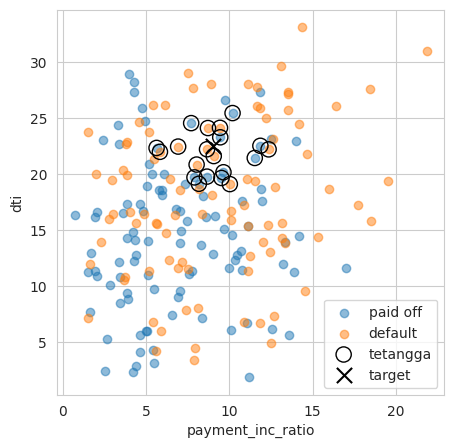

In [4]:
# Visualisasi: pinjaman baru (X) dan tetangganya
plot_data = loan200.copy()
plot_data["is_nbr"] = False
plot_data.loc[X.index[nbrs[1][0]], "is_nbr"] = True

fig, ax = plt.subplots(figsize=(5, 5))
for outcome, color in [("paid off", "C0"), ("default", "C1")]:
    sub = plot_data[plot_data.outcome == outcome]
    ax.scatter(sub.payment_inc_ratio, sub.dti, alpha=0.5, color=color, label=outcome)
nbr = plot_data[plot_data.is_nbr]
ax.scatter(nbr.payment_inc_ratio, nbr.dti, facecolors="none",
           edgecolors="k", s=120, label="tetangga")
ax.scatter(newloan.payment_inc_ratio, newloan.dti, marker="x", color="k", s=120, label="target")
ax.set_xlabel("payment_inc_ratio")
ax.set_ylabel("dti")
ax.legend()
plt.show()

Dalam contoh ini ada 20 tetangga, dan mayoritas atau separuhnya menentukan prediksi. Karena `predict_proba` mengembalikan proporsi tetangga per kelas, kita juga dapat estimasi probabilitas, bukan hanya label.

### Distance Metrics

Kemiripan (kedekatan) ditentukan oleh **distance metric**, fungsi yang mengukur jarak antar dua record (x1, x2, ..., xp) dan (u1, u2, ..., up). Yang paling populer:

- **Euclidean distance**: akar dari jumlah kuadrat selisih tiap fitur.
- **Manhattan distance**: jumlah selisih absolut. Disebut begitu karena jarak antar dua titik di jalan kota yang membentuk grid.

Euclidean lebih peka terhadap selisih besar, sedangkan Manhattan lebih berpegang pada total selisih. Keduanya sama-sama banyak dipakai. Dua metrik lain, Mahalanobis distance dan cosine similarity, juga dipakai pada konteks tertentu.

### One Hot Encoder

Variabel kategorikal harus diubah menjadi numerik sebelum dipakai KNN. Contohnya `purpose_` bisa diubah menjadi kolom-kolom dummy dengan one hot encoding (`pd.get_dummies`). Hal ini juga berlaku ke hampir semua metode berbasis jarak.

### Standardization (Normalization, z-Scores)

Pada pengukuran, variabel dengan skala besar mendominasi jarak. Contoh: `revol_bal` (saldo kredit berputar, dalam dolar) skalanya jauh lebih besar daripada `payment_inc_ratio`. Kalau tidak distandardisasi, jarak hampir hanya ditentukan oleh `revol_bal`.

Standardisasi mengubah tiap variabel menjadi z-score: z = (x − rata-rata) / simpangan baku. Setelah itu tiap variabel berskala sebanding.

In [5]:
# Prediksi dengan prediktor yang skalanya sangat berbeda
loan_data_sub = loan_data.copy()
predictors = ["payment_inc_ratio", "dti", "revol_bal", "revol_util"]
outcome = "outcome"

newloan = loan_data_sub.loc[loan_data_sub.index[0:1], predictors]
X = loan_data_sub.loc[loan_data_sub.index[1:], predictors]
y = loan_data_sub.loc[loan_data_sub.index[1:], outcome]

# Tanpa standardisasi
knn = KNeighborsClassifier(n_neighbors=5).fit(X, y)
print("Tanpa standardisasi:")
print(X.iloc[knn.kneighbors(newloan)[1][0], :])

Tanpa standardisasi:
       payment_inc_ratio   dti  revol_bal  revol_util
35537             1.4721  1.46       1686        10.0
33652             3.3818  6.37       1688         8.4
25864             2.3630  1.39       1691         3.5
42954             1.2816  7.14       1684         3.9
43600             4.1224  8.98       1684         7.2


In [6]:
# Dengan standardisasi (z-score)
scaler = StandardScaler()
scaler.fit(X * 1.0)

X_std = scaler.transform(X * 1.0)
newloan_std = scaler.transform(newloan * 1.0)

knn_std = KNeighborsClassifier(n_neighbors=5).fit(X_std, y)
nbrs = knn_std.kneighbors(newloan_std)
print("Dengan standardisasi:")
print(X.iloc[nbrs[1][0], :])

Dengan standardisasi:
       payment_inc_ratio   dti  revol_bal  revol_util
2081              2.6109  1.03       1218         9.7
1439              2.3434  0.51        278         9.9
30216             2.7120  1.34       1075         8.5
28543             2.3976  0.74       2917         7.4
44738             2.3431  1.37        488         7.2


Perhatikan bedanya: tanpa standardisasi, tetangga hampir sepenuhnya ditentukan oleh `revol_bal` dan nilai variabel lain diabaikan. Setelah standardisasi, kelima variabel ikut berperan dan tetangga yang terpilih jauh lebih masuk akal.

Standardisasi untuk KNN perlu hati-hati. Variabel yang kita anggap lebih penting bisa diberi bobot lebih besar dengan memperbesar skalanya setelah standardisasi.

### Memilih K

Pilihan K sangat memengaruhi kinerja KNN.

- **K = 1** (tetangga tunggal) cenderung overfitting pada noise data latih.
- **K terlalu besar** membuat prediksi terlalu mulus, kehilangan kemampuan menangkap pola lokal (underfitting).

Ini adalah contoh trade-off bias-variance. Secara umum, K kurang dari 20 sering cocok untuk data yang punya sinyal jelas. K yang lebih besar cocok untuk data yang noisy. Untuk memilih nilai K yang baik, bandingkan akurasi pada data validasi untuk beberapa nilai K, atau pakai cross-validation.

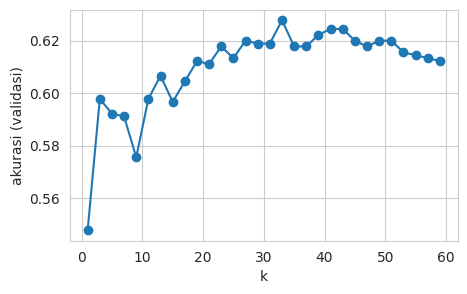

,k,accuracy
16,33,0.6278
21,43,0.6244
20,41,0.6244
19,39,0.6222
13,27,0.6200


In [7]:
# Memilih K dengan data validasi
X_all = pd.get_dummies(loan3000[["payment_inc_ratio", "dti", "borrower_score"]])
y_all = loan3000["outcome"]
X_train, X_valid, y_train, y_valid = train_test_split(
    X_all, y_all, test_size=0.3, random_state=1)

scaler = StandardScaler().fit(X_train)
Xtr, Xva = scaler.transform(X_train), scaler.transform(X_valid)

results = []
for k in range(1, 61, 2):
    knn = KNeighborsClassifier(n_neighbors=k).fit(Xtr, y_train)
    results.append({"k": k, "accuracy": accuracy_score(y_valid, knn.predict(Xva))})
results = pd.DataFrame(results)

ax = results.plot(x="k", y="accuracy", marker="o", figsize=(5, 3), legend=False)
ax.set_ylabel("akurasi (validasi)")
plt.show()
results.sort_values("accuracy", ascending=False).head()

### KNN sebagai Feature Engine

KNN populer karena kesederhanaannya dan kemampuannya menangkap pola lokal. Pada beberapa masalah, KNN memberi prediksi yang cukup baik di data latih, sehingga hasilnya bisa dipakai sebagai **fitur tambahan** untuk model lain. Caranya:

1. KNN dijalankan pada data dengan beberapa prediktor, untuk tiap record menghasilkan probabilitas/skor tetangga.
2. Skor itu ditambahkan sebagai kolom fitur baru.
3. Model lain (misalnya tree atau logistic regression) memakai fitur ini.

Praktiknya sering disebut model bertingkat. Pada tiap record, tetangga dihitung dari record lain (bukan dirinya sendiri) untuk menghindari kebocoran informasi.

**Ide kunci:**

- KNN mengklasifikasi record berdasarkan kelas mayoritas dari K tetangga terdekat.
- Pilihan metrik jarak dan standardisasi variabel sangat menentukan hasil.
- K dipilih lewat validasi, mempertimbangkan trade-off antara overfitting dan oversmoothing.
- KNN sering dipakai sebagai tahap awal atau sebagai penghasil fitur untuk model lain.

## 2. Tree Models

Model tree (juga disebut **CART**, classification and regression trees, atau decision trees) adalah alat klasifikasi dan regresi yang kuat dan populer. Tree menghasilkan serangkaian aturan if-then yang mudah dipahami dan diterapkan.

Istilah penting:

- **Recursion**: mengulangi proses yang sama berkali-kali.
- **Split value**: nilai prediktor yang membagi record jadi dua bagian.
- **Node**: simpul pohon, mewakili aturan split.
- **Leaf**: simpul akhir yang menentukan prediksi.
- **Loss**: ukuran kesalahan klasifikasi pada split.
- **Impurity**: ukuran seberapa campur kelas di satu partisi.
- **Pruning**: memangkas cabang untuk mengurangi overfitting.

### Algoritma Partisi Rekursif

Ide dasar: bagi data berulang kali ke dalam partisi dengan nilai prediktor, sehingga tiap partisi menjadi semakin "bersih" (lebih homogen) dalam hal outcome.

Untuk prediktor X dan nilai split s, record dibagi jadi partisi A (X ≤ s) dan B (X > s). Algoritma mencoba semua prediktor dan semua nilai split, lalu memilih pasangan yang membuat partisi paling homogen. Proses diulang pada tiap partisi hasil sampai tidak ada lagi split yang layak.

### Mengukur Homogenitas atau Impurity

Dua ukuran impurity yang umum:

- **Gini impurity**: I(A) = p(1 − p), dengan p proporsi misklasifikasi pada partisi A. Makin rendah makin murni.
- **Entropy**: I(A) = −p log2(p) − (1 − p) log2(1 − p). Juga makin rendah makin murni.

Pengukuran impurity memberi bobot sebanding ukuran partisi, sehingga split yang menghasilkan partisi kecil tetapi sangat murni tidak otomatis menang.

### Contoh Tree

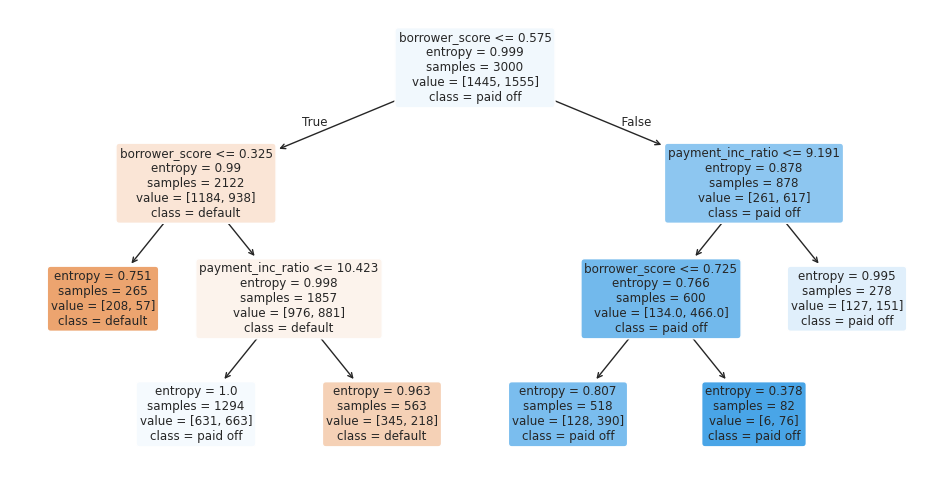

In [8]:
predictors = ["borrower_score", "payment_inc_ratio"]
outcome = "outcome"

X = loan3000[predictors]
y = loan3000[outcome]

loan_tree = DecisionTreeClassifier(random_state=1, criterion="entropy",
                                    min_impurity_decrease=0.003)
loan_tree.fit(X, y)

fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(loan_tree, feature_names=predictors, class_names=list(loan_tree.classes_),
          filled=True, rounded=True, ax=ax)
plt.show()

In [9]:
# Aturan dalam bentuk teks, lebih mudah dibaca dan diterapkan
print(export_text(loan_tree, feature_names=predictors))

|--- borrower_score <= 0.58
|   |--- borrower_score <= 0.33
|   |   |--- class: default
|   |--- borrower_score >  0.33
|   |   |--- payment_inc_ratio <= 10.42
|   |   |   |--- class: paid off
|   |   |--- payment_inc_ratio >  10.42
|   |   |   |--- class: default
|--- borrower_score >  0.58
|   |--- payment_inc_ratio <= 9.19
|   |   |--- borrower_score <= 0.72
|   |   |   |--- class: paid off
|   |   |--- borrower_score >  0.72
|   |   |   |--- class: paid off
|   |--- payment_inc_ratio >  9.19
|   |   |--- class: paid off



Cara membaca tree: mulai dari root. Pada tiap node, ikuti cabang kiri kalau kondisi benar dan kanan kalau salah, sampai mencapai leaf. Kelas mayoritas leaf menjadi prediksi. Model tree mudah dijelaskan, tidak butuh asumsi distribusi, dan menangkap hubungan non-linear serta interaksi secara otomatis.

### Menghentikan Pertumbuhan Tree

Kalau dibiarkan, tree tumbuh sampai tiap leaf murni, yang berarti overfitting. Pendekatan untuk menghentikannya:

- Jangan split partisi kalau ukurannya di bawah ambang tertentu (`min_samples_split`, `min_samples_leaf`).
- Jangan buat split baru kalau tidak memberi perbaikan impurity cukup besar (`min_impurity_decrease`).
- Batasi kedalaman (`max_depth`).

Buku R memakai parameter kompleksitas `cp` dan pemangkasan dengan cross-validation. Di scikit-learn, cara yang praktis adalah mencari kombinasi hyperparameter lewat `GridSearchCV`. Keluaran terbaik dipilih berdasarkan skor cross-validation.

In [10]:
param_grid = {
    "max_depth": [5, 10, 15, 20, 25, 30],
    "min_samples_split": [20, 40, 60, 80, 100],
    "min_impurity_decrease": [0, 0.001, 0.002, 0.003, 0.005, 0.01],
}
grid = GridSearchCV(DecisionTreeClassifier(random_state=1),
                    param_grid, cv=5, n_jobs=-1)
grid.fit(X, y)

print("Skor terbaik:", grid.best_score_)
print("Parameter terbaik:", grid.best_params_)

Skor terbaik: 0.6123333333333333
Parameter terbaik: {'max_depth': 5, 'min_impurity_decrease': 0, 'min_samples_split': 20}


### Memprediksi Nilai Kontinu (Regression Tree)

Prediksi nilai kontinu dengan tree disebut **regression tree**. Mekanismenya sama, tetapi:

- Nilai prediksi di leaf adalah **rata-rata** response record di leaf itu.
- Ukuran impurity diganti dengan variansi (atau deviasi kuadrat dari rata-rata leaf), dan pemilihan split meminimalkan jumlahnya.

Di scikit-learn memakai `DecisionTreeRegressor`.

### Interpretasi Tree

Kelebihan utama tree: dapat dipakai sebagai alat visual untuk eksplorasi dan menjelaskan aturan keputusan. Aturan yang dihasilkan juga bisa diterapkan tanpa komputer, hanya pakai if-then. Tree menangkap interaksi dan non-linearitas tanpa perlu dispesifikasikan oleh analis. Kelemahannya: satu tree cenderung tidak stabil dan prediksinya kurang akurat dibanding metode ensemble di bawah.

**Ide kunci:**

- Tree menghasilkan aturan if-then lewat partisi rekursif prediktor.
- Split dipilih untuk meminimalkan impurity (Gini atau entropy).
- Tree yang dibiarkan tumbuh penuh akan overfitting, jadi pertumbuhannya perlu dibatasi atau dipangkas.
- Tree mudah dijelaskan, tetapi prediksinya sering kalah dari ensemble.

## 3. Bagging dan Random Forest

Pada 1906, Francis Galton meneliti lomba menaksir berat sapi di sebuah pameran. Rata-rata taksiran 800 orang hampir tepat (hanya selisih sekitar 1 pon), lebih baik daripada taksiran ahli kebanyakan. Ini contoh **wisdom of crowds**: rata-rata banyak prediksi cenderung lebih akurat dibanding satu prediksi.

Istilah penting:

- **Ensemble**: membentuk prediksi dengan menggabungkan banyak model.
- **Averaging**: menggabungkan prediksi (rata-rata atau suara mayoritas).
- **Bagging**: **b**ootstrap **agg**regat**ing**, membuat banyak model dari sampel bootstrap.
- **Random forest**: bagging terhadap tree dengan sampling acak kolom prediktor pada tiap split.
- **Variable importance**: ukuran pentingnya prediktor dalam model.

### Bagging

Algoritmanya:

1. Tentukan jumlah model M dan ukuran sampel (n).
2. Ambil sampel bootstrap (dengan pengembalian) dari data.
3. Latih model pada sampel itu.
4. Ulangi M kali.
5. Gabungkan prediksi semua model: rata-rata (regresi) atau suara mayoritas (klasifikasi).

Hasilnya biasanya lebih akurat dan lebih stabil daripada satu model, terutama untuk model yang variansinya tinggi seperti tree.

### Random Forest

Random forest adalah bagging pada decision tree dengan satu tambahan penting: **pada tiap split, hanya sebagian kecil prediktor yang dipilih acak sebagai kandidat**. Ini membuat tree-tree yang dihasilkan lebih beragam (kurang berkorelasi), sehingga rata-ratanya lebih bagus.

Algoritma secara garis besar:

1. Ambil sampel bootstrap.
2. Saat membuat tiap split, pilih acak p < P prediktor sebagai kandidat.
3. Tumbuhkan tree sampai selesai.
4. Ulangi, lalu rata-ratakan.

In [11]:
predictors = ["borrower_score", "payment_inc_ratio"]
outcome = "outcome"
X = loan3000[predictors]
y = loan3000[outcome]

rf = RandomForestClassifier(n_estimators=500, random_state=1, oob_score=True)
rf.fit(X, y)
print("OOB accuracy:", rf.oob_score_)

OOB accuracy: 0.5753333333333334


### Out-of-Bag Estimate of Error

Karena tiap tree dilatih pada sampel bootstrap, sekitar sepertiga record tidak ikut dipakai untuk tree itu (out-of-bag, OOB). Record OOB dipakai sebagai data uji "gratis" untuk menaksir error tanpa perlu data validasi terpisah. Di scikit-learn, aktifkan dengan `oob_score=True`. Kita bisa mengamati bagaimana error OOB berubah saat jumlah tree bertambah.

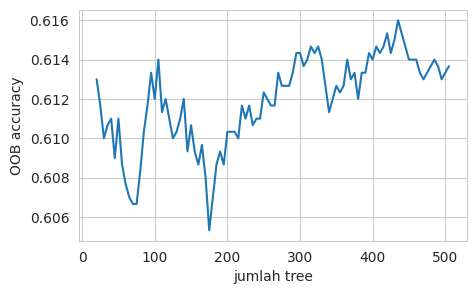

In [12]:
n_estimator = list(range(20, 510, 5))
oob_scores = []
for n in n_estimator:
    rf_n = RandomForestClassifier(n_estimators=n, criterion="entropy",
                                  max_depth=5, random_state=1, oob_score=True)
    rf_n.fit(X, y)
    oob_scores.append(rf_n.oob_score_)

ax = pd.DataFrame({"n": n_estimator, "oob": oob_scores}).plot(
    x="n", y="oob", figsize=(5, 3), legend=False)
ax.set_xlabel("jumlah tree")
ax.set_ylabel("OOB accuracy")
plt.show()

Akurasi OOB meningkat lalu mendatar seiring bertambahnya tree, menandakan tambahan tree tidak lagi memberi manfaat besar.

### Variable Importance

Random forest unggul untuk dataset dengan banyak prediktor. Untuk mengetahui prediktor mana yang paling berperan, dipakai **variable importance**. Ada dua ukuran umum:

- **Penurunan akurasi (permutation importance)**: acak urutan nilai satu prediktor lalu lihat seberapa turun akurasi. Makin besar penurunan, makin penting prediktor itu.
- **Penurunan impurity rata-rata (Gini)**: total pengurangan impurity akibat split pada prediktor tersebut.

Pengukuran Gini lebih cepat tetapi bisa bias ke variabel dengan banyak nilai unik. Permutation lebih andal tetapi lebih mahal.

Di bawah ini model dilatih pada lebih banyak prediktor dari `loan_data`.

In [13]:
predictors = ["loan_amnt", "term", "annual_inc", "dti", "payment_inc_ratio",
              "revol_bal", "revol_util", "purpose", "delinq_2yrs_zero",
              "pub_rec_zero", "open_acc", "grade", "emp_length", "purpose_",
              "home_", "emp_len_", "borrower_score"]
# Hanya pakai kolom yang benar-benar ada di data
predictors = [c for c in predictors if c in loan_data.columns]
print(predictors)

outcome = "outcome"
X = pd.get_dummies(loan_data[predictors], drop_first=True)
y = loan_data[outcome]

rf_all = RandomForestClassifier(n_estimators=100, random_state=1,
                                max_depth=8, n_jobs=-1)
rf_all.fit(X, y)

imp = pd.DataFrame({"fitur": X.columns,
                    "gini_importance": rf_all.feature_importances_})
imp = imp.sort_values("gini_importance", ascending=False).head(10)
imp

['loan_amnt', 'term', 'annual_inc', 'dti', 'payment_inc_ratio', 'revol_bal', 'revol_util', 'purpose', 'delinq_2yrs_zero', 'pub_rec_zero', 'open_acc', 'grade', 'emp_length', 'purpose_', 'home_', 'emp_len_', 'borrower_score']


,fitur,gini_importance
11,borrower_score,0.2586
9,grade,0.2137
12,term_60 months,0.1151
3,payment_inc_ratio,0.1017
1,annual_inc,0.0737
5,revol_util,0.0517
2,dti,0.0458
0,loan_amnt,0.0291
4,revol_bal,0.0229
29,purpose__small_business,0.0130


In [14]:
from sklearn.inspection import permutation_importance

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=1)
rf_all.fit(X_tr, y_tr)

perm = permutation_importance(rf_all, X_te, y_te, n_repeats=5,
                              random_state=1, n_jobs=-1)
perm_df = pd.DataFrame({"fitur": X.columns,
                        "penurunan_akurasi": perm.importances_mean})
perm_df.sort_values("penurunan_akurasi", ascending=False).head(10)

,fitur,penurunan_akurasi
11,borrower_score,0.0461
9,grade,0.0230
12,term_60 months,0.0173
1,annual_inc,0.0066
3,payment_inc_ratio,0.0032
29,purpose__small_business,0.0015
21,purpose_small_business,0.0008
13,purpose_credit_card,0.0007
24,purpose__debt_consolidation,0.0005
8,open_acc,0.0005


### Hyperparameters

Random forest, seperti banyak algoritma machine learning, adalah kotak hitam dengan parameter pengaturan yang disebut **hyperparameter**, yang diatur sebelum fitting dan bukan dioptimasi saat training. Dua yang paling penting pada random forest:

- `max_features`: jumlah prediktor yang dipilih acak pada tiap split.
- `min_samples_leaf`: ukuran minimum leaf. Nilai lebih besar mengurangi overfitting.

Defaultnya biasanya sudah bagus, tetapi menyetelnya bisa meningkatkan kinerja.

**Ide kunci:**

- Ensemble membentuk prediksi dengan merata-ratakan banyak model.
- Bagging adalah ensemble yang melatih model pada sampel bootstrap.
- Random forest menambah sampling acak prediktor di tiap split.
- Variable importance mengukur kontribusi prediktor, dan error OOB memberi estimasi error tanpa data uji terpisah.

## 4. Boosting

Ensemble juga bisa dibangun dengan **boosting**. Berbeda dengan bagging yang melatih model secara independen, boosting melatih model secara **berurutan**: tiap model baru memberi perhatian lebih pada record yang sulit diprediksi model sebelumnya.

Istilah penting:

- **Boosting**: ensemble yang bertahap, tiap model memperbaiki sisa kesalahan model sebelumnya.
- **Adaboost**: boosting yang menaikkan bobot record yang salah diklasifikasi.
- **Gradient boosting**: boosting yang dirumuskan sebagai optimasi fungsi biaya.
- **Stochastic gradient boosting**: gradient boosting dengan sampling record dan kolom di tiap putaran.
- **Regularization**: menambahkan penalti jumlah parameter model untuk mencegah overfitting.
- **Hyperparameters**: parameter yang perlu diatur sebelum fitting.

### Algoritma Boosting

Versi umum: ada beberapa model M1, M2, ... yang dibangun berurutan.

1. Latih model pertama pada data.
2. Cari record yang salah diprediksi, lalu beri bobot lebih besar.
3. Latih model berikutnya pada data berbobot itu.
4. Ulangi sampai jumlah model tercapai.
5. Gabungkan semua model dengan bobot sesuai akurasinya.

**Adaboost** menaikkan bobot record yang salah klasifikasi dengan faktor tertentu dan memberi bobot lebih besar ke model yang akurat. **Gradient boosting** serupa, tetapi memandang masalahnya sebagai optimasi: tiap model baru dilatih untuk memprediksi **residual** (sisa kesalahan) ensemble sejauh ini, dengan **learning rate** yang mengecilkan kontribusi tiap model baru.

### XGBoost

Implementasi gradient boosting yang paling populer adalah **XGBoost**, yang cepat, fleksibel, dan punya banyak opsi regularisasi. Salah satu detail penting: memakai subsampling (`subsample`) di tiap putaran, sehingga menjadi stochastic gradient boosting.

In [15]:
# pip install xgboost
from xgboost import XGBClassifier

predictors = ["borrower_score", "payment_inc_ratio"]
outcome = "outcome"

X = loan3000[predictors]
y = loan3000[outcome].cat.codes   # xgboost butuh label numerik (0/1)

xgb = XGBClassifier(objective="binary:logistic", subsample=0.63,
                    eval_metric="logloss", random_state=1)
xgb.fit(X, y)

pred = xgb.predict_proba(X)[:, 1]
print(pd.Series(pred).describe())

count    3000.0000
mean        0.5205
std         0.2490
min         0.0052
25%         0.3401
50%         0.5244
75%         0.7000
max         0.9989
dtype: float64


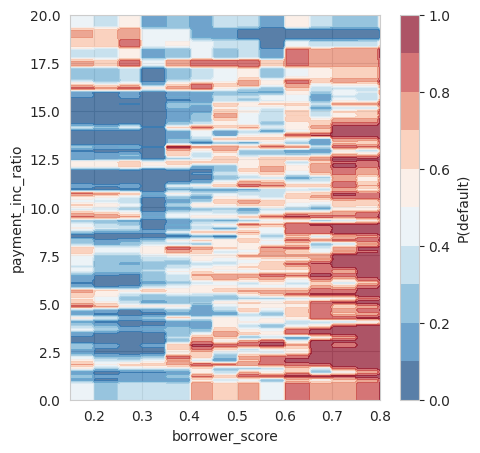

In [16]:
# Visualisasi aturan prediksi: peta probabilitas di ruang dua prediktor
xx, yy = np.meshgrid(np.linspace(0.15, 0.8, 100), np.linspace(0, 20, 100))
grid_df = pd.DataFrame({"borrower_score": xx.ravel(),
                        "payment_inc_ratio": yy.ravel()})
zz = xgb.predict_proba(grid_df)[:, 1].reshape(xx.shape)

fig, ax = plt.subplots(figsize=(5, 5))
c = ax.contourf(xx, yy, zz, levels=10, cmap="RdBu_r", alpha=0.7)
plt.colorbar(c, ax=ax, label="P(default)")
ax.set_xlabel("borrower_score")
ax.set_ylabel("payment_inc_ratio")
plt.show()

### Regularization: Menghindari Overfitting

Boosting yang dibiarkan tanpa batas akan overfitting. Salah satu penyebabnya adalah model bisa menyesuaikan diri terhadap noise. Cara membatasinya:

- **Regularisasi**: XGBoost menambah penalti pada kompleksitas tree lewat `reg_alpha` (L1) dan `reg_lambda` (L2). Makin besar, model makin sederhana.
- **Learning rate (`learning_rate`, `eta`)**: nilai lebih kecil membuat tiap tree berkontribusi lebih sedikit sehingga lebih konservatif.
- **Subsampling**: memakai sebagian record di tiap putaran.

Pengaruhnya bisa dilihat dengan membandingkan model default dengan model teregularisasi pada data yang lebih besar. Buku memakai 25 prediktor dan membandingkan error pada data latih dan data uji.

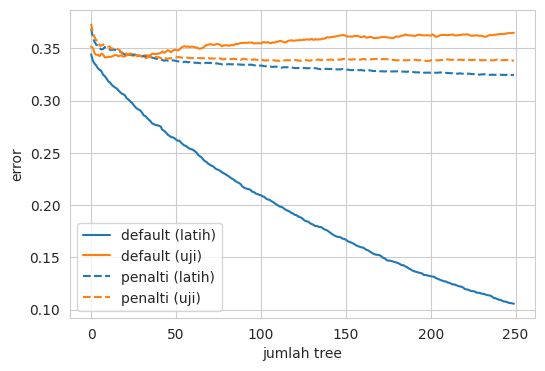

In [17]:
predictors = [c for c in ["loan_amnt", "term", "annual_inc", "dti",
                          "payment_inc_ratio", "revol_bal", "revol_util",
                          "purpose_", "home_", "emp_len_", "borrower_score"]
              if c in loan_data.columns]
X = pd.get_dummies(loan_data[predictors], drop_first=True).astype(float)
y = (loan_data["outcome"] == "default").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1)

xgb_default = XGBClassifier(n_estimators=250, max_depth=6, reg_lambda=0,
                            learning_rate=0.3, subsample=1,
                            eval_metric="error", random_state=1)
xgb_default.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_test, y_test)],
                verbose=False)

xgb_penalty = XGBClassifier(n_estimators=250, max_depth=6, reg_lambda=1000,
                            learning_rate=0.1, subsample=0.63,
                            eval_metric="error", random_state=1)
xgb_penalty.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_test, y_test)],
                verbose=False)

def eval_curve(model):
    r = model.evals_result()
    return r["validation_0"]["error"], r["validation_1"]["error"]

fig, ax = plt.subplots(figsize=(6, 4))
for name, m, style in [("default", xgb_default, "-"), ("penalti", xgb_penalty, "--")]:
    tr, te = eval_curve(m)
    ax.plot(tr, style, color="C0", label=f"{name} (latih)")
    ax.plot(te, style, color="C1", label=f"{name} (uji)")
ax.set_xlabel("jumlah tree")
ax.set_ylabel("error")
ax.legend()
plt.show()

Pada model default, error data latih terus turun sementara error data uji berhenti membaik atau malah naik: tanda overfitting. Model dengan regularisasi punya selisih latih-uji yang jauh lebih kecil, dan error ujinya biasanya lebih stabil.

Catatan versi: di xgboost versi lama, jumlah tree yang dipakai saat prediksi diatur dengan `ntree_limit`. Argumen itu sudah dihapus di versi baru. Sebagai gantinya pakai `iteration_range=(0, i)` pada `predict`.

### Hyperparameters dan Cross-Validation

XGBoost punya banyak hyperparameter. Yang paling berpengaruh:

- `learning_rate` (`eta`): ukuran langkah tiap tree.
- `max_depth`: kedalaman maksimum tree. Tree dangkal (misalnya 3 sampai 6) umum di boosting.
- `n_estimators`: jumlah tree.
- `subsample`, `colsample_bytree`: porsi record dan kolom per putaran.
- `reg_lambda`, `reg_alpha`: kekuatan regularisasi.

Karena banyak parameter, kombinasi terbaik dicari lewat cross-validation. Tujuannya menemukan kombinasi yang error validasinya terendah. Contoh berikut mencoba kombinasi `learning_rate` dan `max_depth`.

In [18]:
import itertools
from sklearn.model_selection import cross_val_score

scores = []
for eta, depth in itertools.product([0.1, 0.5, 0.9], [3, 6, 9]):
    model = XGBClassifier(n_estimators=100, learning_rate=eta, max_depth=depth,
                          subsample=0.63, eval_metric="logloss", random_state=1)
    acc = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy").mean()
    scores.append({"learning_rate": eta, "max_depth": depth, "accuracy_cv": acc})

cv_results = pd.DataFrame(scores)
cv_results.pivot(index="max_depth", columns="learning_rate", values="accuracy_cv")

learning_rate,0.1,0.5,0.9
max_depth,,,
3,0.6593,0.6506,0.6392
6,0.6566,0.6181,0.5946
9,0.6443,0.6065,0.5880


Tabel di atas menunjukkan akurasi cross-validation untuk tiap kombinasi. Pilih kombinasi dengan nilai terbaik, lalu latih ulang pada seluruh data latih dan evaluasi sekali pada data uji.

Buku menutup bagian ini dengan peringatan: jangan menyetel hyperparameter berlebihan pada data yang sama sampai performanya terlihat bagus hanya karena kebetulan (overfitting terhadap validasi). Gunakan data uji terpisah yang tidak dipakai selama penyetelan.

**Ide kunci:**

- Boosting melatih model berurutan, tiap model fokus pada kesalahan sebelumnya.
- Gradient boosting (XGBoost) adalah pendekatan paling populer dan paling kuat untuk data terstruktur.
- Regularisasi, learning rate kecil, dan subsampling mencegah overfitting.
- Hyperparameter perlu disetel dengan cross-validation.

## Poin-poin Penting Bab 6

- KNN memprediksi lewat tetangga terdekat. Standardisasi variabel dan pilihan K sangat menentukan hasil.
- Decision tree menghasilkan aturan if-then yang mudah dijelaskan, tetapi satu tree cenderung overfitting dan tidak stabil.
- Bagging dan random forest merata-ratakan banyak tree dari sampel bootstrap. Random forest menambah sampling acak prediktor di tiap split dan menyediakan error OOB serta variable importance.
- Boosting membangun model berurutan. XGBoost adalah implementasi gradient boosting yang populer, dengan regularisasi untuk mengendalikan overfitting.
- Hyperparameter (K, kedalaman tree, learning rate, dan sebagainya) perlu disetel lewat cross-validation, dengan data uji terpisah untuk evaluasi akhir.

Referensi: Bruce, P., Bruce, A., & Gedeck, P. (2020). *Practical Statistics for Data Scientists*, 2nd ed., Bab 6 "Statistical Machine Learning". O'Reilly Media.